# Israel Doctors EDA — Portfolio review

This notebook reproduces selected **published summary exports** from the repository. It does **not** re-extract PDF tables, independently audit clinical records, run SQL Server, or regenerate the full v22 pipeline. See [Research validation](../RESEARCH_VALIDATION.md) and the [original investigation](Israel_Doctors_EDA_Exploration_22.ipynb).

**Run:** From the `analysis/` directory after installing `requirements.txt`. All charts and tables below read version-controlled CSV exports. Numbers marked PROVISIONAL remain exploratory.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EXPORTS = Path("exports")
if not EXPORTS.is_dir():
    raise FileNotFoundError("Run this notebook from the analysis/ directory.")

def read_export(filename):
    return pd.read_csv(EXPORTS / filename, encoding="utf-8-sig")

## 1 · Missing-data interpolation sensitivity

The primary 2021 training association is unchanged by interpolation; another pair gains a reporting country and changes modestly. This does not establish correctness of imputed values.

In [2]:
sensitivity = read_export("OECD_2021_Interpolation_Sensitivity.csv")
display(sensitivity)

#,version,metric_pair,countries_n,pearson_r
0,original,foreign_pct vs graduates_100k,27,-0.3582693977441985
1,original,foreign_pct vs practising_1k,25,-0.13197467733139454
2,original,graduates_100k vs practising_1k,31,0.2204260662092119
3,original,ALL THREE (sample size only),24,
4,interpolated,foreign_pct vs graduates_100k,27,-0.3582693977441985
5,interpolated,foreign_pct vs practising_1k,25,-0.13197467733139454
6,interpolated,graduates_100k vs practising_1k,32,0.2704298595661554
7,interpolated,ALL THREE (sample size only),24,


## 2 · Physician stock is not the same as practising physicians

The stock-by-training series and the practising-physicians series use different definitions. Their growth rates should not be compared as interchangeable measures.

In [3]:
growth = read_export("Israel_2010_2024_population_physician_growth_summary.csv")
display(growth)

2010,2024,#,measure,change_pct
7623600.0,10002200.0,0,Population (persons),31.200482711579824
10306.0,15044.0,1,Domestic-trained physicians (stock),45.973219483795845
15466.0,21777.0,2,Foreign-trained physicians (stock),40.805638174059226
25772.0,36821.0,3,Combined training stocks (persons),42.87210926586993
1.3518547667768508,1.5040691047969448,4,"Domestic stock / 1,000",11.259666479041218
2.028700351539955,2.177221011377497,5,"Foreign stock / 1,000",7.320975703720967
3.380555118316806,3.681290116174442,6,"Combined stock / 1,000",8.896024094627798
3.01,3.64,7,"Practising physicians / 1,000 (separate series)",20.93023255813955


## 3 · The OECD benchmark depends on country coverage

In 2021, Israel reported 3.39 practising physicians per 1,000 people. The median among 32 reporting OECD countries was 3.79; the fixed 26-country panel median was 3.53. The implied counts are **benchmark-equivalent differences**, not estimates of a clinically justified shortage.

In [4]:
bench = read_export("OECD_2021_Israel_Practising_Physicians_Benchmarks.csv")
display(bench)
fixed = read_export("OECD_2010_2024_Israel_vs_fixed_medians.csv")
fixed_2021 = fixed[(fixed["year"] == 2021) & (fixed["metric"] == "practising_per_1000")]
display(fixed_2021)

#,benchmark,oecd_countries_reporting,benchmark_practising_per_1000,israel_practising_per_1000,gap_per_1000,equivalent_extra_practising_physicians_israel_population
0,OECD median (reporting countries),32,3.79,3.39,0.3999999999999999,3749
1,OECD mean (reporting countries),32,3.771875,3.39,0.38187499999999996,3579
2,Highest reported country (descriptive),32,5.42,3.39,2.03,19024


#,year,metric,series,value,OECD_reporting_countries_n,fixed_countries_n
123,2021,practising_per_1000,Israel,3.39,32,26
124,2021,practising_per_1000,OECD available-case median,3.79,32,26
125,2021,practising_per_1000,OECD fixed-country median,3.53,32,26


## 4 · Hospital-level correlations (2021)

Only 21–24 hospitals contribute to each correlation. All measures are hospital **process** indicators and remain provisional pending data-definition verification.

#,metric,n_hospitals,pearson_r,exploratory_p,spearman_rho,n_hospitals_50plus_cases,pearson_r_50plus
0,CHADS,21,-0.1277901573751631,0.5809338788254729,-0.31113999692307426,21,-0.1277901573751631
1,Colon antibiotics,24,-0.1744615878352771,0.41487851000709836,-0.09185895515690902,15,-0.24429788755226742
2,Hip fracture 48h,23,0.2949915210002187,0.1717908367712786,0.3391003874499617,23,0.2949915210002187


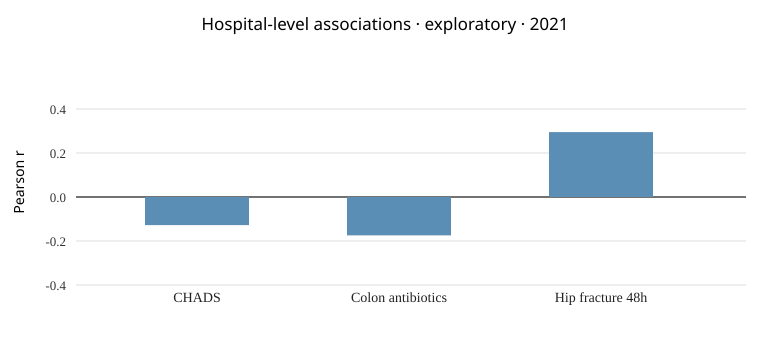

In [5]:
hospital = read_export("MOH_2021_training_quality_correlations_PROVISIONAL.csv")
display(hospital)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(hospital["metric"], hospital["pearson_r"])
ax.axhline(0, linewidth=1)
ax.set_ylabel("Pearson r")
ax.set_title("Hospital-level associations · exploratory · 2021")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 5 · Specialty-level correlations (2020): hypotheses, not confirmation

Cardiology/CHADS has a strong nominal correlation in a small sample (n=9). It is not statistically significant after correcting the three reported comparisons at a family-wise 5% level, and specialty extraction, denominator sizes, hospital composition and CHADS responsibility remain unverified.

In [6]:
specialty = read_export("MOH_2020_specialty_vs_2020_quality_pearson_PROVISIONAL.csv")
display(specialty)
leave_one_out = read_export("MOH_2020_Cardiology_CHADS_Leave_One_Out.csv")
display(leave_one_out.sort_values("pearson_r"))
print("Range of leave-one-hospital-out correlations:", leave_one_out["pearson_r"].min(), leave_one_out["pearson_r"].max())

#,specialty_he,metric_short,n_hospitals,pearson_r,pearson_p_value
0,קרדיולוגיה,CHADS,9,-0.7504344039303302,0.019830295663452322
1,כירורגיה כללית,Colon antibiotics,10,-0.19125496864936925,0.5966001580651564
2,כירורגיה אורתופדית,Hip fracture 48h,10,0.4447829980791137,0.1977488937539266


#,excluded_hospital,remaining_hospitals,pearson_r,nominal_p_value
0,Soroka,8,-0.8448617765415696,0.008282198711817033
1,Kaplan,8,-0.7906104684674118,0.019497812881153282
2,Rambam,8,-0.7763658314804448,0.023481079188316246
3,Shaare Zedek,8,-0.7760912796943066,0.02356240578512729
4,Meir,8,-0.7396995068670562,0.03593267870937491
5,Hadassah EK,8,-0.727653623879047,0.040747998415289664
6,Sourasky,8,-0.7248526401576616,0.041920789389055815
7,Sheba,8,-0.7212027407078728,0.043479414961192064
8,Shamir,8,-0.6295589396009823,0.09439345694794148


Range of leave-one-hospital-out correlations: -0.8448617765415696 -0.6295589396009823


## 6 · Missing numerators: hip-fracture source-record audit

The audit supports interpreting some blank numerators as zero documented successes; it does not independently confirm every metric or resolve the recorded exactly-48-hour boundary. **Records are not necessarily individual patients.**

In [7]:
hip_audit = read_export("MOH_Hip_Blank_Numerator_Time_Audit.csv")
display(hip_audit)

#,category,source_records,cases_in_records
0,all_blank_numerators,1470,1499.0
1,blank_and_time_gt48,1355,1383.0
2,blank_and_time_eq48,115,116.0
3,blank_and_time_lt48,0,0
4,all_time_gt48,1355,1383.0
5,all_time_lt48,11214,11494.0
6,time_eq48_with_reported_numerator,6,6.0


## Interpretation checklist

- No ecological hospital-level association proves the quality of an individual physician.
- Training origin is not randomly assigned; differences in hospital resources, patient severity and speciality can confound comparisons.
- Do not confuse the OECD foreign-trained stock with graduates affected by the specific Yatziv reform restrictions.
- A failure to detect statistical significance is **not** evidence that the true relationship must be zero.
- No original SQL scripts are asserted by this review notebook; the legacy database is separate.

For underlying exploration and charts, use the [original notebook](Israel_Doctors_EDA_Exploration_22.ipynb).